# Input data preparation

## Accepts .h5 and .imzml formats

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import cv2
from natsort import natsorted, ns
from hyres_utils import hyres_generator
from hyres_evals import entropy_rank, info_montage

### Input directory
this is the directory that contains your .imzml, .h5 .tif etc.

In [2]:
input_dir = 'C:/Users/LocalAdmin/Dropbox/File requests/PPserver/validation/A30_Centroid'

### Generate HR input/training images from HSI datasets in input directory

In [3]:
files = natsorted(
    [f for f in glob.glob(os.path.join(input_dir, '*'))
     if os.path.splitext(f)[1].lower() in ('.h5', '.imzml')],
    alg=ns.IGNORECASE)

for file in files:
    fmt = 'imzml' if file.lower().endswith('.imzml') else 'h5'
    _, _ = hyres_generator(os.path.basename(file), input_dir, file_format=fmt, bin_width =0.1)

n_h5 = sum(f.lower().endswith('.h5') for f in files)
n_imzml = len(files) - n_h5
print('training images generated from %d datasets (%d h5, %d imzML).'
      % (len(files), n_h5, n_imzml))

### Visualise the top 10 features in the HSI dataset that contain the most representative information (by Shannon's entropy)

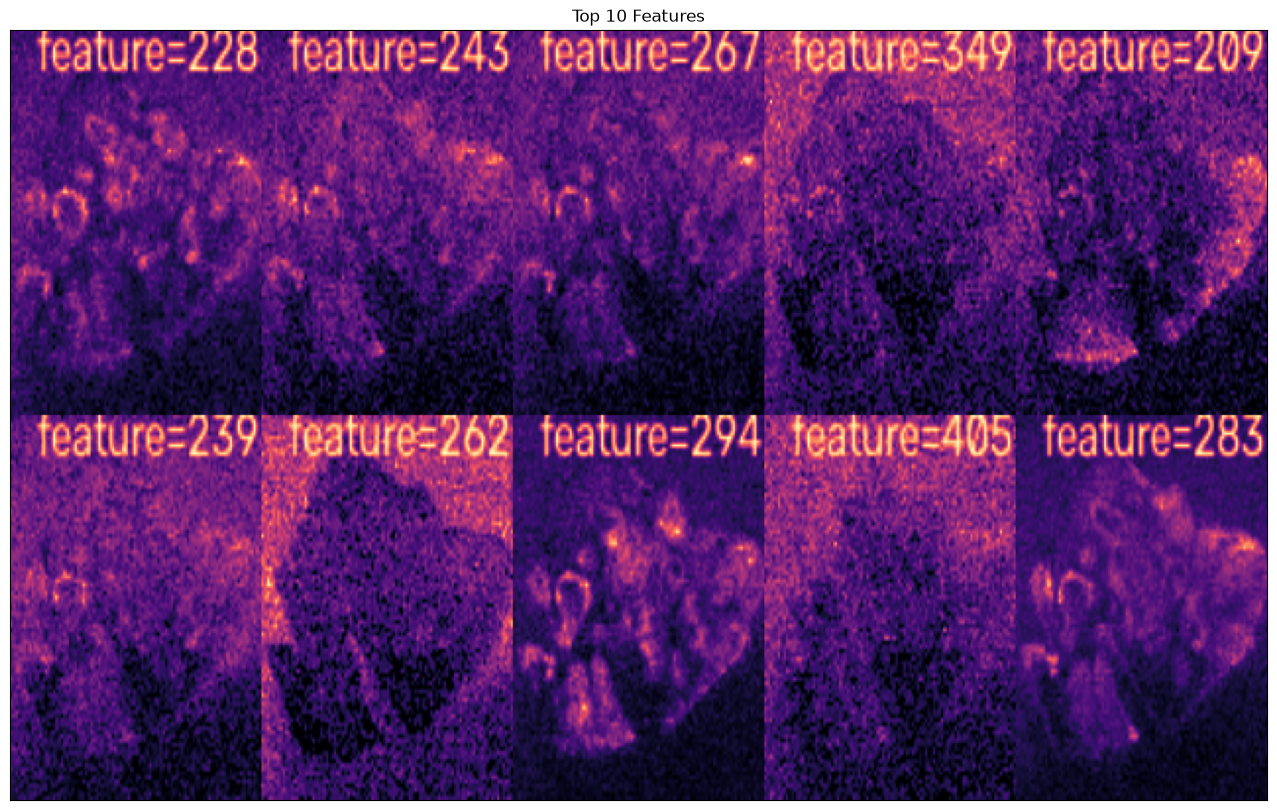

In [4]:
example_dir = os.path.splitext(files[0])[0]
ents, rank = entropy_rank(example_dir)

montages = info_montage(example_dir, rank)
for montage in montages:
    fig, ax = plt.subplots()
    ax.set_title('Top 10 Features')
    ax.set_xticks([]) 
    ax.set_yticks([])  
    ax.imshow(cv2.cvtColor(montage, cv2.COLOR_BGR2GRAY), cmap = 'magma');
    fig = plt.gcf()
    fig.set_size_inches(20, 10)

### Generate synthetic LR images to pair with HR images for training